# The guesstimate: clarify, map, calculate, validate: how big is an unknown?

**Week 4, Tuesday, concept notebook 4 of 5, beside chapter 6 of the deck.** The campus
canteen, its till, the town, the phone pack and Gulmohar Secondary School's exam are
invented, and every number about them in this notebook was written by the day's seeded
generator.

**Who needs the answer.** The canteen head (invented), who must order milk for a weekday
before any till report exists, and any interviewer who asks for a number aloud. A guess
nobody can check orders too much milk or too little, and an interviewer scores the thinking
before the number.

**The questions on the way.** Who scores higher, the chain or the near guess? What exactly
is counted, and which factors multiply into it? Which guess sets the range? Is the answer
sane against the till? What does a sanity check catch that careful arithmetic misses?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# The canteen's three guesses, its till for one week, and three checks gone wrong; all invented
ledger = pd.read_csv("../data/C2_W04_D02_canteen_ledger_STUDENT.csv").set_index("factor")
till = pd.read_csv("../data/C2_W04_D02_canteen_till_STUDENT.csv")
tests = pd.read_csv("../data/C2_W04_D02_sanity_tests_STUDENT.csv")
check("three factors in the ledger, each with a low and a high", len(ledger) == 3 and (ledger.low < ledger.high).all())
check("five weekdays on the till", len(till) == 5)
print(ledger.to_string())
print(till.to_string(index=False))
print(tests.to_string(index=False))

PASS three factors in the ledger, each with a low and a high
PASS five weekdays on the till
                                central      low     high               unit                                    why
factor                                                                                                             
students on campus              3000.00  2700.00  3300.00           students         the campus head count, rounded
share who buy tea on a weekday     0.45     0.25     0.65  share of students  a guess from the queue at the counter
cups each buyer drinks             2.00     1.50     2.50       cups a buyer    one in the morning, one after lunch
  weekday  cups_sold
   Monday       2295
  Tuesday       2380
Wednesday       2310
 Thursday       2375
   Friday       2340
      test                                example              quantity   value     unit
      unit                                 a town                people 24000.0   people
      unit              

## Who scores higher, the chain or the near guess?

A **guesstimate** is a rough count of something nobody has measured; an **assumption** is a
guess said aloud with its range; the **range** is the lowest and highest answer you would
still defend. Write your own number for the cups of tea the canteen sells on a weekday
before you read on. Then two candidates answer.

**Candidate A:** "Students on campus times the share who buy tea times cups each: 3,000 x
0.45 x 2 = 2,700 cups. Checked against the till it runs high, so the share is the guess I
would replace with a count first."

**Candidate B:** "About 2,350 cups."

**Predict before you run.** The till's five weekdays average 2,340 cups. Who scores higher?

a) B, because 2,350 sits ten cups from the till
b) A, because the chain and the check show how the number was built
c) They score the same, because both landed near the till
d) Neither, because a number with no data cannot be marked

factor
students on campus                3000
share who buy tea on a weekday    1350
cups each buyer drinks            2700
candidate A: 2,700 cups, 15.4% above the till's 2,340
PASS by hand and by code, the chain gives 2,700 cups
PASS candidate B lands nearer the till than A


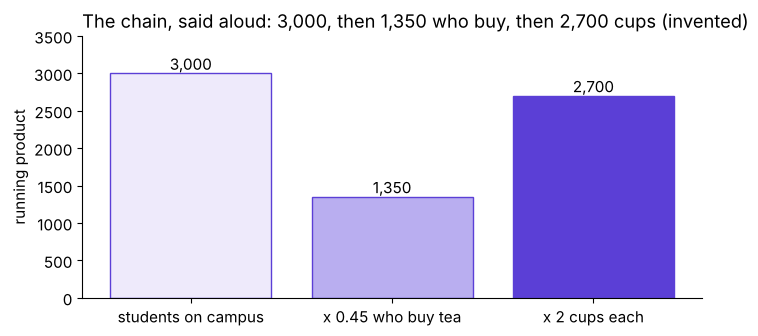

In [2]:
# Clarify: one canteen, one weekday, cups of tea. Map: students x share who buy x cups each.
running = ledger.central.cumprod()                      # the running product, said aloud
print(running.round(0).astype(int).to_string())
cups = ledger.central.prod()
by_hand = 3000 * 0.45 * 2
gap_a = cups / till.cups_sold.mean() - 1
print(f"candidate A: {cups:,.0f} cups, {gap_a:.1%} above the till's {till.cups_sold.mean():,.0f}")
check("by hand and by code, the chain gives 2,700 cups", cups == by_hand == 2700)
check("candidate B lands nearer the till than A", abs(2350 - till.cups_sold.mean()) < abs(cups - till.cups_sold.mean()))

fig, ax = plt.subplots(figsize=(8, 3.4))
steps = ["students on campus", "x 0.45 who buy tea", "x 2 cups each"]
bars = ax.bar(steps, running, color=[PALE, LILAC, VIOLET], edgecolor=VIOLET)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in running])
ax.set_ylim(0, 3500)
ax.set_ylabel("running product")
ax.set_title("The chain, said aloud: 3,000, then 1,350 who buy, then 2,700 cups (invented)", loc="left")
plt.show()

**What happened.** The answer is b. B lands nearer the till, and still scores lower: its
2,350 cannot be checked, defended or improved, while A's 2,700 shows which guess to replace.
Think Insights' guide to guesstimates says the interviewer "is interested in your thought
process; not the final result", and that the best candidates "validate their results & try
to spot their own mistake before telling their interviewer they are done".

Units multiply as well as numbers: students x (buyers per student) x (cups per buyer) =
cups. Writing the unit beside each factor is how the chain is checked before it is
calculated.

## Which guess sets the range?

Move one guess at a time to its low end and its high end, holding the other two at their
central values. The widest bar is the guess to replace with a count first.

**Predict before you run.** Which guess moves the answer most?

a) Students on campus
b) The share who buy tea
c) Cups each buyer drinks
d) All three move it equally

                                 low  high
students on campus              2430  2970
cups each buyer drinks          2025  3375
share who buy tea on a weekday  1500  3900
PASS the share who buy sets the range: 1,500 to 3,900


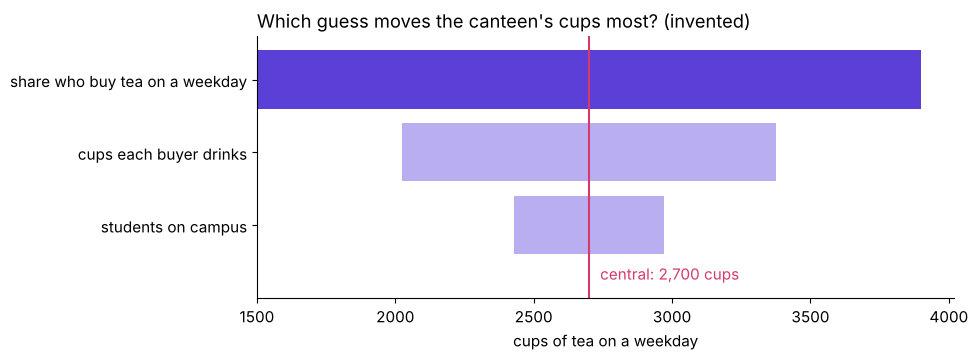

In [3]:
def swing(ledger):
    """Each factor moved to its low and its high end, the others held at their central values."""
    out = {}
    for factor in ledger.index:
        ends = []
        for end in ("low", "high"):
            values = ledger.central.copy()
            values[factor] = ledger.loc[factor, end]
            ends.append(values.prod())
        out[factor] = ends
    return pd.DataFrame(out, index=["low", "high"]).T

sw = swing(ledger)
sw["width"] = sw.high - sw.low
sw = sw.sort_values("width")
print(sw[["low", "high"]].round(0).astype(int).to_string())
check("the share who buy sets the range: 1,500 to 3,900", sw.index[-1] == "share who buy tea on a weekday"
      and sw.loc["share who buy tea on a weekday", ["low", "high"]].tolist() == [1500, 3900])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(sw.index, sw.width, left=sw.low, color=[LILAC, LILAC, VIOLET])
ax.axvline(cups, color=ROSE)
ax.set_ylim(-1.0, 2.6)
ax.text(cups + 40, -0.75, f"central: {cups:,.0f} cups", color=ROSE)
ax.set_xlabel("cups of tea on a weekday")
ax.set_title("Which guess moves the canteen's cups most? (invented)", loc="left")
plt.show()

**What happened.** The answer is b. With the other two held, students move the answer from
2,430 to 2,970, cups each from 2,025 to 3,375, and the share who buy from 1,500 to 3,900.
Say it as: "about 2,700 cups, 1,500 to 3,900 by the share who buy." A range more than twice
its low end tells the canteen head which number to count before ordering.

## Is the answer sane against the till?

A **check** is a number someone counted, in the same unit, the same period and the same
definition as the estimate. The till counts cups of tea sold on a weekday, so it passes all
three tests.

**Predict before you run.** The chain says 2,700 and the till 2,340. Which guess should
move?

a) Students on campus, since the head count may be stale
b) The share who buy, since it sets the range and the till sits inside it
c) Cups each, since nobody drinks exactly two
d) None: the till must be wrong, since the chain was careful

the till: 2,340 cups a weekday; the chain runs 15.4% high
the share that lands on the till: 0.39
PASS the till sits inside the share's range
PASS the share the till implies is 0.39


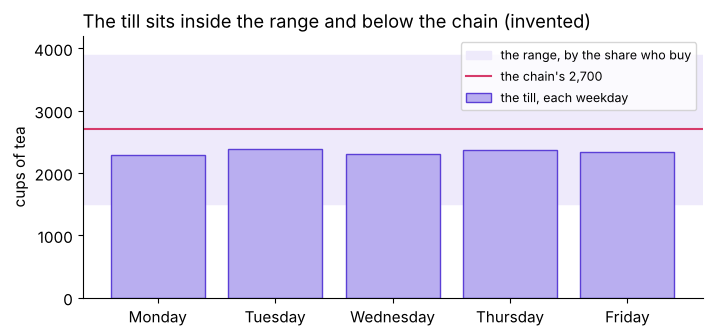

In [4]:
till_mean = till.cups_sold.mean()
implied_share = till_mean / (ledger.loc["students on campus", "central"] * ledger.loc["cups each buyer drinks", "central"])
print(f"the till: {till_mean:,.0f} cups a weekday; the chain runs {gap_a:.1%} high")
print(f"the share that lands on the till: {implied_share:.2f}")
check("the till sits inside the share's range", sw.loc["share who buy tea on a weekday", "low"] <= till_mean
      <= sw.loc["share who buy tea on a weekday", "high"])
check("the share the till implies is 0.39", round(implied_share, 2) == 0.39)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axhspan(1500, 3900, color=PALE, label="the range, by the share who buy")
ax.bar(till.weekday, till.cups_sold, color=LILAC, edgecolor=VIOLET, label="the till, each weekday")
ax.axhline(cups, color=ROSE, label="the chain's 2,700")
ax.set_ylim(0, 4200)
ax.set_ylabel("cups of tea")
ax.set_title("The till sits inside the range and below the chain (invented)", loc="left")
ax.legend(loc="upper right", fontsize=9)
plt.show()

**What happened.** The answer is b. The chain runs 15.4 percent above the till's 2,340, and
the share that lands on the till is 0.39: 3,000 x 0.39 x 2 = 2,340. The share is the widest
guess and the one the till contradicts, so it moves; the canteen head now has a number she
can order milk on and a reason for it.

## What does a sanity check catch that careful arithmetic misses?

**The plausible wrong answer.** "A town of 24,000 people (invented) has 96,000 households."
Size a household business on it and the market is sixteen times too large. A hurried chain
multiplies where it should divide, and every step after it is careful.

hurried: 96,000 households from 24,000 people; right: 6,000
PASS the hurried count fails the first test: households never exceed people
PASS the fix divides: about 6,000 households
period: the pack 42 GB against a month's 45 GB, and 1.5 GB a day in both
definition: 113 passes are 83.7% of those who sat and 75.3% of those enrolled
PASS per day, the pack and the month agree
PASS the two pass rates differ by the denominator alone


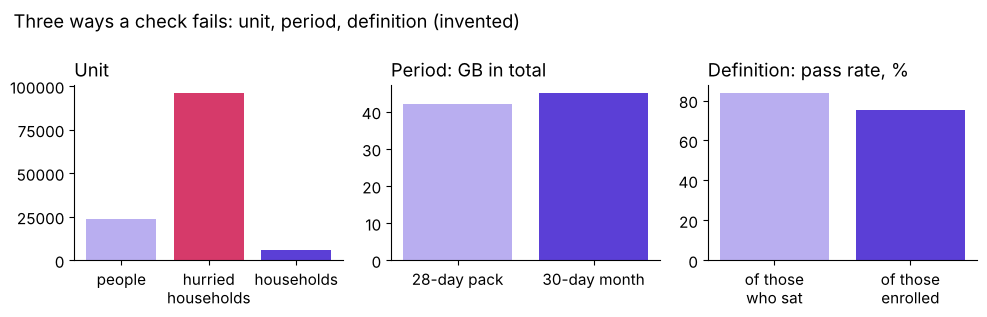

In [5]:
t = tests.set_index(["test", "quantity"]).value
people, per_household = t["unit", "people"], t["unit", "people to a household"]
hurried = people * per_household                      # the unit multiplied where it should be divided
right = people / per_household
print(f"hurried: {hurried:,.0f} households from {people:,.0f} people; right: {right:,.0f}")
check("the hurried count fails the first test: households never exceed people", hurried > people)
check("the fix divides: about 6,000 households", right == 6000)

gb_day, pack_days, month_days = t["period", "data a day"], t["period", "days in the pack"], t["period", "days in a month"]
print(f"period: the pack {gb_day * pack_days:.0f} GB against a month's {gb_day * month_days:.0f} GB, "
      f"and {gb_day} GB a day in both")
enrolled = t["definition", "students enrolled"]
sat, passed = t["definition", "students who sat"], t["definition", "students who passed"]
print(f"definition: {passed:.0f} passes are {passed / sat:.1%} of those who sat and {passed / enrolled:.1%} of those enrolled")
check("per day, the pack and the month agree", gb_day * pack_days / pack_days == gb_day * month_days / month_days)
check("the two pass rates differ by the denominator alone", round(passed / sat * 100, 1) == 83.7 and round(passed / enrolled * 100, 1) == 75.3)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].bar(["people", "hurried\nhouseholds", "households"], [people, hurried, right], color=[LILAC, ROSE, VIOLET])
axes[0].set_title("Unit", loc="left")
axes[1].bar(["28-day pack", "30-day month"], [gb_day * pack_days, gb_day * month_days], color=[LILAC, VIOLET])
axes[1].set_title("Period: GB in total", loc="left")
axes[2].bar(["of those\nwho sat", "of those\nenrolled"], [passed / sat * 100, passed / enrolled * 100], color=[LILAC, VIOLET])
axes[2].set_title("Definition: pass rate, %", loc="left")
fig.suptitle("Three ways a check fails: unit, period, definition (invented)", x=0.02, ha="left")
fig.tight_layout()
plt.show()

**Why it is wrong.** Households are people divided by about four, so the town has about
6,000; the chain multiplied the unit, and nothing after it could repair that. **The
check:** households never exceed people. **The fix:** write the unit beside every factor
before multiplying. The other two tests fail the same quiet way: a 28-day pack of 1.5 GB a
day is 42 GB and a 30-day month at the same rate is 45 GB, so compare per day; Gulmohar's
113 passes are 83.7 percent of the 135 who sat and 75.3 percent of the 150 enrolled, so use
the denominator the question names.

Named last, the four steps the canteen ran: **clarify** the unit, the period and what
counts; **map** the answer as a chain of factors; **calculate** each factor aloud with its
range; **validate** against a number counted in the same unit, period and definition. That
is the guesstimate: clarify, map, calculate, validate. The function below is the last
step, and it refuses a comparison that fails any of the three tests.

In [6]:
def validate(estimate, known, same_unit, same_period, same_definition):
    """The gap between an estimate and a counted number, or no verdict when the comparison is unfair."""
    if not (same_unit and same_period and same_definition):
        return "not a check"
    return f"{estimate / known - 1:+.1%}"

print("the till:", validate(cups, till_mean, True, True, True))
print("the campus head count:", validate(cups, ledger.loc["students on campus", "central"], False, True, True))
check("the till is a check", validate(cups, till_mean, True, True, True) != "not a check")
check("a head count is no check on cups", validate(cups, 3000, False, True, True) == "not a check")

the till: +15.4%
the campus head count: not a check
PASS the till is a check
PASS a head count is no check on cups


**Your turn.** Re-run the chain with the share the till implies and show that it lands on
the till; then say the range it would carry if the share's ends stay where they were. Fill
the blank, type the lines into the empty cell below and run them:

```python
moved = ledger.copy()
moved.loc["share who buy tea on a weekday", "central"] = ___
new_cups = moved.central.prod()
print(round(new_cups))
check("the chain with the till's share lands on the till", abs(new_cups - till_mean) < 1)
```

## Which rules does the chapter leave?

1. Clarify the unit, the period and what counts before writing any number.
2. Map the answer as a chain of factors that multiplies out in the unit you clarified.
3. Say each factor aloud with its range, and name the factor that sets the range.
4. Validate against a number counted in the same unit, period and definition, and move the
   answer if the check says so.

**In the interview.** [S] A guesstimate: how many customers could a new store sign up to a
loyalty tier in its first year? The structure, the stated assumptions and the check carry
most of the score.

**Where it is used next.** Chapter 8's notebook,
`C2_W04_D02_08_case_guesstimate_drivers_at_peak_STUDENT.ipynb`, sizes the drivers Uber
needs online at the evening peak with the same four steps, and the lab's notebook 11 sizes
a new Kalpa store's sign-ups.